# 01 · Data Exploration — Prices & Machine Loads

**Project:** Industrial Load Shifting · **Author:** Swaroop Jadhav

### Purpose
Before modelling anything, I want to understand both datasets and answer a few simple business questions. Each chart below answers one of them, followed by my interpretation.

### Business questions for this notebook
1. How much do 15-minute electricity prices vary — is there money to save at all?
2. When is electricity cheap or expensive during a typical day?
3. How does that change across the seasons?
4. How much energy does each machine use, and when?
5. Which machines *look* flexible (first guess — confirmed in notebook 02)?

**Prerequisites:** run `python src/download_prices.py` and `python src/load_machine_data.py` first.

In [1]:
import calendar
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent / "src"))   # so we can import config.py
import config

# ---- Chart style: clean, readable, consistent -----------------------------
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#898781", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "lines.linewidth": 2, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 12,
})
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight")

---
## Part A · Electricity prices

### A1. First look at the data
Always start with: *How many rows? Which columns? Which data types? Anything missing?*

**Units:** prices are in **€/MWh**. 1 MWh = 1,000 kWh, so **€/MWh ÷ 10 = cents per kWh**.
Example: 100 €/MWh = 10 ct/kWh.

In [2]:
prices = pd.read_csv(config.PRICES_RAW_FILE, parse_dates=["timestamp_utc"])
prices["timestamp_local"] = prices["timestamp_utc"].dt.tz_convert(config.LOCAL_TZ)

print(f"Rows: {len(prices):,}   (one year of quarter-hours = 365 x 96 = 35,040)")
print(f"Period: {prices['timestamp_local'].min()}  ->  {prices['timestamp_local'].max()}")
print(f"Missing prices: {prices['price_eur_mwh'].isna().sum()}")
prices.head()

Rows: 35,040   (one year of quarter-hours = 365 x 96 = 35,040)
Period: 2025-10-01 00:00:00+02:00  ->  2026-09-30 23:45:00+02:00
Missing prices: 0


,timestamp_utc,timestamp_local,price_eur_mwh
0,2025-09-30 22:00:00+00:00,2025-10-01 00:00:00+02:00,102.60
1,2025-09-30 22:15:00+00:00,2025-10-01 00:15:00+02:00,92.24
2,2025-09-30 22:30:00+00:00,2025-10-01 00:30:00+02:00,86.03
3,2025-09-30 22:45:00+00:00,2025-10-01 00:45:00+02:00,85.39
4,2025-09-30 23:00:00+00:00,2025-10-01 01:00:00+02:00,89.99


In [3]:
# Add helper columns we will use again and again ("feature engineering")
p = prices.set_index("timestamp_local")
prices["date"] = p.index.date
prices["month"] = p.index.month
prices["hour"] = p.index.hour
prices["quarter_of_day"] = p.index.hour * 4 + p.index.minute // 15   # 0..95
prices["is_weekend"] = p.index.day_of_week >= 5
prices["price_ct_kwh"] = prices["price_eur_mwh"] / 10

prices["price_eur_mwh"].describe().round(2)

count    35040.00
mean       104.05
std         63.19
min       -499.99
25%         78.18
50%        103.96
75%        136.33
max        747.10
Name: price_eur_mwh, dtype: float64

### A2. Question 1 — How much do prices vary? Is there money to save?
The key number for load shifting is the **daily spread**: the difference between the cheapest and
the most expensive quarter-hour **on the same day**. A machine that can move within a day can
capture part of this spread.

In [4]:
daily = prices.groupby("date")["price_eur_mwh"].agg(["min", "max", "mean"])
daily["spread"] = daily["max"] - daily["min"]

kpis = {
    "Average price (€/MWh)": prices["price_eur_mwh"].mean(),
    "Lowest quarter-hour (€/MWh)": prices["price_eur_mwh"].min(),
    "Highest quarter-hour (€/MWh)": prices["price_eur_mwh"].max(),
    "Quarter-hours with negative price": (prices["price_eur_mwh"] < 0).sum(),
    "Average daily spread max-min (€/MWh)": daily["spread"].mean(),
    "Days with spread > 100 €/MWh": (daily["spread"] > 100).sum(),
}
pd.Series(kpis).round(1).to_frame("value")

,value
Average price (€/MWh),104.0
Lowest quarter-hour (€/MWh),-500.0
Highest quarter-hour (€/MWh),747.1
Quarter-hours with negative price,2052.0
Average daily spread max-min (€/MWh),164.4
Days with spread > 100 €/MWh,257.0


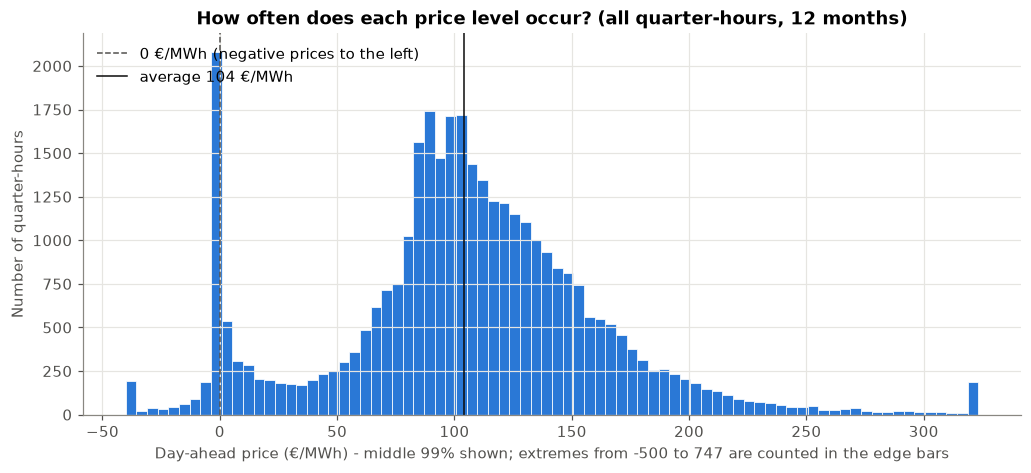

In [5]:
# Zoom in: the extremes (-500 / +747) would squeeze the chart, so we show the middle 99%
low, high = prices["price_eur_mwh"].quantile([0.005, 0.995])
fig, ax = plt.subplots()
ax.hist(prices["price_eur_mwh"].clip(low, high), bins=80, color=COLORS[0], edgecolor="white", linewidth=0.5)
ax.axvline(0, color="#52514e", linewidth=1, linestyle="--", label="0 €/MWh (negative prices to the left)")
ax.axvline(prices["price_eur_mwh"].mean(), color="#0b0b0b", linewidth=1,
           label=f"average {prices['price_eur_mwh'].mean():.0f} €/MWh")
ax.legend(frameon=False, loc="upper left")
ax.set(title="How often does each price level occur? (all quarter-hours, 12 months)",
       xlabel=f"Day-ahead price (€/MWh) - middle 99% shown; extremes from {prices['price_eur_mwh'].min():.0f} "
              f"to {prices['price_eur_mwh'].max():.0f} are counted in the edge bars",
       ylabel="Number of quarter-hours")
save(fig, "A2_price_distribution")
plt.show()

**Interpretation**

Yes, there is clearly money to save. The average price over the year was about 104 €/MWh, but the average daily spread (most expensive minus cheapest quarter-hour on the same day) was 164 €/MWh, so even higher than the average price itself. On 257 of 365 days (around 70%) the spread was above 100 €/MWh, so big price differences are not rare, they happen on most days.

Negative prices were more common than I expected: 2,052 quarter-hours, which is about 6% of the year (roughly 513 hours). Most prices are still in a normal range though: half of all quarter-hours are between about 78 and 136 €/MWh.

### A3. Question 2 — When is electricity cheap during a typical day?
We average the price for each of the 96 quarter-hours of the day, separately for weekdays and
weekends (factories mostly run on weekdays).

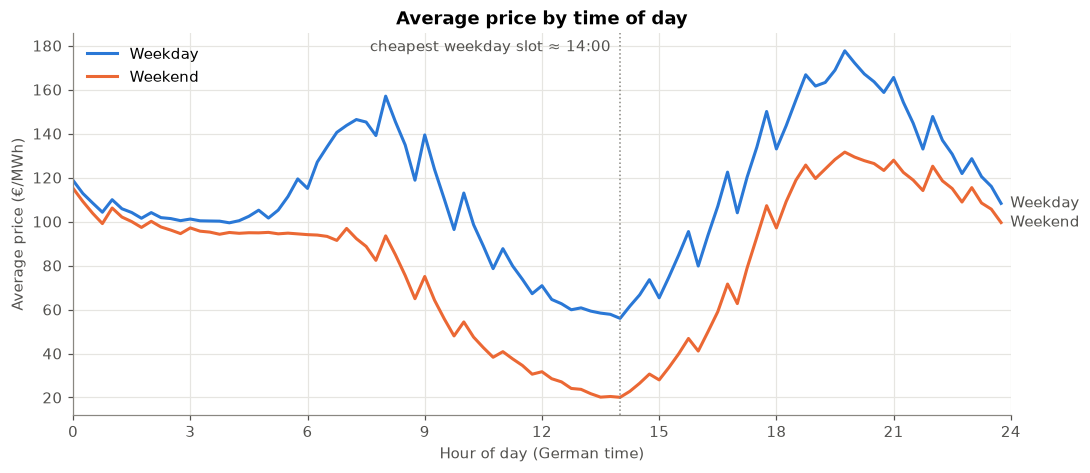

In [6]:
profile = (prices.groupby(["quarter_of_day", "is_weekend"])["price_eur_mwh"]
           .mean().unstack().rename(columns={False: "Weekday", True: "Weekend"}))
x_hours = profile.index / 4

fig, ax = plt.subplots()
for i, col in enumerate(profile.columns):
    ax.plot(x_hours, profile[col], color=COLORS[i], label=col)
    ax.annotate(col, xy=(x_hours[-1], profile[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", color="#52514e", va="center")
cheapest = profile["Weekday"].idxmin() / 4
ax.axvline(cheapest, color="#898781", linewidth=1, linestyle=":")
ax.annotate(f"cheapest weekday slot ≈ {int(cheapest):02d}:{int(cheapest % 1 * 60):02d}",
            xy=(cheapest, ax.get_ylim()[1]), xytext=(-6, -4), textcoords="offset points",
            color="#52514e", va="top", ha="right")
ax.set(title="Average price by time of day", xlabel="Hour of day (German time)",
       ylabel="Average price (€/MWh)", xticks=range(0, 25, 3), xlim=(0, 24))
ax.legend(frameon=False, loc="upper left")
save(fig, "A3_daily_price_profile")
plt.show()

**Interpretation**

On weekdays the cheapest time is around 14:00 with about 57 €/MWh on average, and the most expensive is the evening around 20:00 with about 178 €/MWh, so roughly 3 times higher. There is also a smaller morning peak around 8:00 (~155 €/MWh), when demand goes up but solar is not producing much yet.

The midday dip comes from solar: when solar output is highest there is a lot of supply, so the price drops. After sunset the solar supply disappears while demand is still high, which is why prices jump in the evening. Weekends have the same shape but are lower overall (down to ~20 €/MWh at midday) because industrial demand is lower. For a factory this is interesting because 14:00 is still inside a normal day shift.

### A4. Question 3 — How does the daily pattern change through the year?
A **heatmap**: each row is a month, each column an hour; darker = more expensive.

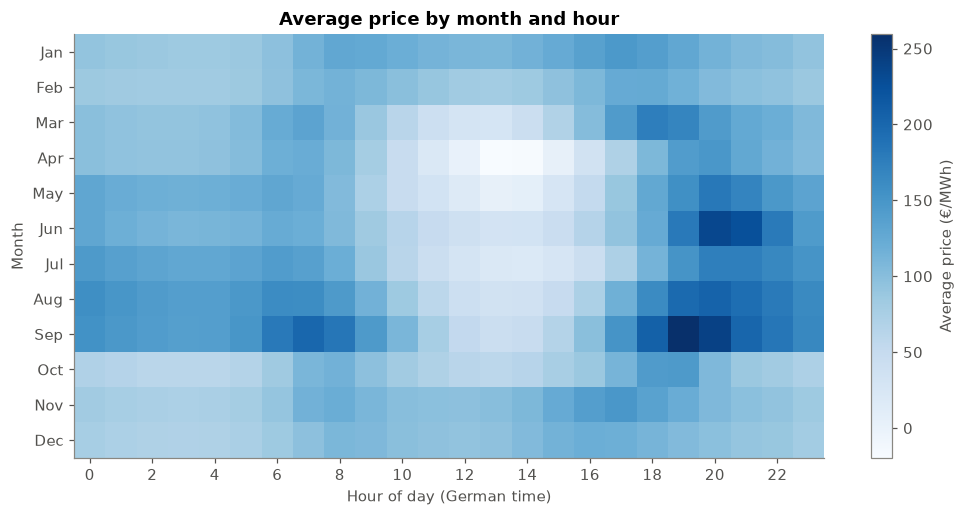

In [7]:
heat = prices.groupby(["month", "hour"])["price_eur_mwh"].mean().unstack()
month_names = [calendar.month_abbr[m] for m in heat.index]

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(heat.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels(range(0, 24, 2))
ax.set_yticks(range(len(heat))); ax.set_yticklabels(month_names)
ax.grid(False)
cbar = fig.colorbar(im, ax=ax); cbar.set_label("Average price (€/MWh)")
ax.set(title="Average price by month and hour", xlabel="Hour of day (German time)", ylabel="Month")
save(fig, "A4_price_heatmap")
plt.show()

**Interpretation**

The midday dip is strongest in spring, especially March to May. April has the lowest midday prices, close to 0 €/MWh on average around 13:00. In summer (June to September) midday is still cheap, but the evenings get very expensive: the darkest cells are around 19:00 to 21:00 in June and September (roughly 200 to 250 €/MWh). From October to February the pattern is much flatter, with almost no midday dip because there is less sun, and the peak moves earlier to the late afternoon.

So in spring and summer a factory would gain a lot by running energy-heavy jobs around midday and avoiding the evening. In winter, shifting within the day saves much less. One thing to keep in mind: Oct–Dec in this data is from 2025 and Jan–Sep from 2026, so the months come from two different years.

---
## Part B · Machine loads (HIPE, KIT production plant)

### B1. First look
**Units:** **kW** = power (how hard a machine works *right now*);
**kWh** = energy (power × time — what you pay for). 10 kW for 15 minutes = 10 × 0.25 = 2.5 kWh.

In [8]:
loads = pd.read_csv(config.MACHINE_LOAD_FILE, parse_dates=["timestamp_utc"])
loads["timestamp_local"] = loads["timestamp_utc"].dt.tz_convert(config.LOCAL_TZ)

print(f"Machines: {loads['machine'].nunique()}  ->  {sorted(loads['machine'].unique())}")
print(f"Period:   {loads['timestamp_local'].min()}  ->  {loads['timestamp_local'].max()}")
print(f"Quarter-hours with no readings: {loads['avg_kw'].isna().sum()}")
loads.head()

Machines: 11  ->  ['ChipPress', 'ChipSaw', 'HighTemperatureOven', 'MainTerminal', 'PickAndPlaceUnit', 'ScreenPrinter', 'SolderingOven', 'VacuumOven', 'VacuumPump1', 'VacuumPump2', 'WashingMachine']
Period:   2017-10-23 00:00:00+02:00  ->  2017-10-29 23:45:00+01:00
Quarter-hours with no readings: 0


,timestamp_utc,machine,avg_kw,energy_kwh,sample_count,timestamp_local
0,2017-10-22 22:00:00+00:00,ChipPress,-0.0,-0.0,164,2017-10-23 00:00:00+02:00
1,2017-10-22 22:15:00+00:00,ChipPress,-0.0,-0.0,164,2017-10-23 00:15:00+02:00
2,2017-10-22 22:30:00+00:00,ChipPress,-0.0,-0.0,164,2017-10-23 00:30:00+02:00
3,2017-10-22 22:45:00+00:00,ChipPress,-0.0,-0.0,163,2017-10-23 00:45:00+02:00
4,2017-10-22 23:00:00+00:00,ChipPress,-0.0,-0.0,162,2017-10-23 01:00:00+02:00


⚠️ **Important:** the `MainTerminal` meter measures the **whole plant** — it already *contains* the other
machines. It must not be added to the machine totals (that would count the same energy twice).

In [9]:
is_main = loads["machine"].str.contains("Main", case=False)
machines = loads[~is_main]

summary = machines.groupby("machine").agg(
    avg_kw=("avg_kw", "mean"), peak_kw=("avg_kw", "max"), energy_kwh=("energy_kwh", "sum"))
summary["share_of_machine_energy_%"] = 100 * summary["energy_kwh"] / summary["energy_kwh"].sum()
if is_main.any():
    plant_kwh = loads.loc[is_main, "energy_kwh"].sum()
    print(f"Whole plant (main terminal): {plant_kwh:,.0f} kWh  |  measured machines cover "
          f"{100 * summary['energy_kwh'].sum() / plant_kwh:.0f}% of it")
summary.sort_values("energy_kwh", ascending=False).round(1)

Whole plant (main terminal): 2,714 kWh  |  measured machines cover 4% of it


,avg_kw,peak_kw,energy_kwh,share_of_machine_energy_%
machine,,,,
SolderingOven,0.2,5.6,32.4,31.3
VacuumPump1,0.2,0.9,29.1,28.1
HighTemperatureOven,0.1,6.4,12.4,12.0
VacuumPump2,0.1,0.8,11.5,11.1
ChipSaw,0.0,0.5,7.2,6.9
PickAndPlaceUnit,0.0,0.3,6.6,6.4
ScreenPrinter,0.0,0.3,4.3,4.1
VacuumOven,0.0,0.0,0.2,0.2
WashingMachine,0.0,0.0,0.1,0.1


### B2. Question 4 — When does each machine run?
One small chart per machine (*small multiples*): same time axis, each with its own scale,
so small machines are still readable.

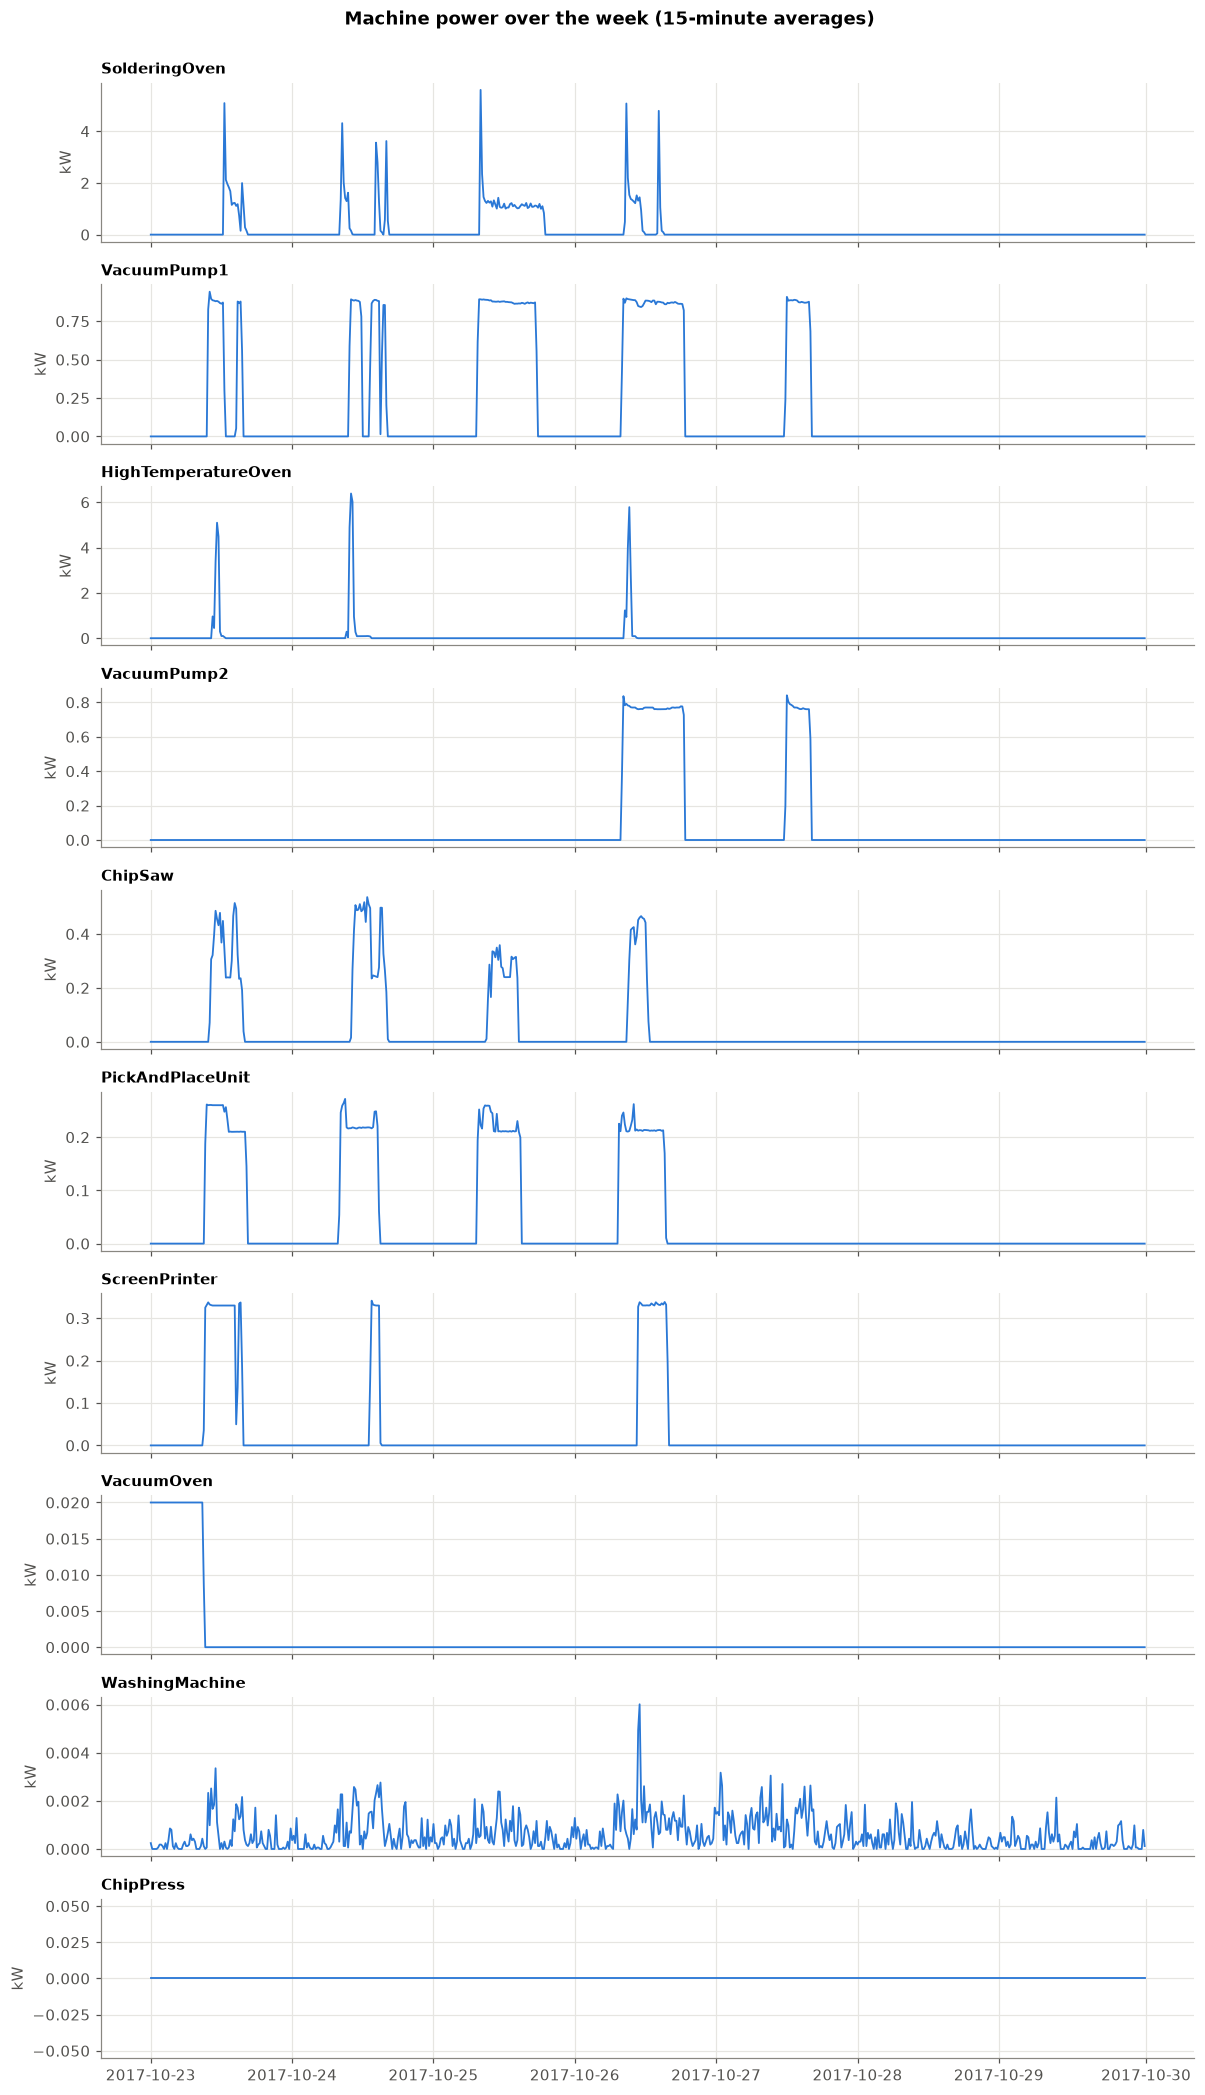

In [10]:
names = summary.sort_values("energy_kwh", ascending=False).index
fig, axes = plt.subplots(len(names), 1, figsize=(11, 1.9 * len(names)), sharex=True)
axes = np.atleast_1d(axes)
for ax, name in zip(axes, names):
    m = machines[machines["machine"] == name]
    ax.plot(m["timestamp_local"], m["avg_kw"], color=COLORS[0], linewidth=1.2)
    ax.set_title(name, loc="left", fontsize=10)
    ax.set_ylabel("kW")
fig.suptitle("Machine power over the week (15-minute averages)", fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "B2_machine_profiles")
plt.show()

**Interpretation**

All machines run only on weekdays (23 to 27 Oct) and during the day. Nothing runs at night or on the weekend (28 and 29 Oct), so the plant clearly follows a day-shift pattern. None of the machines runs constantly. They all work in batches and are completely off in between.

Some batches are longer, for example VacuumPump1 runs in blocks of several hours, while the HighTemperatureOven only has three short spikes of high power. The SolderingOven and VacuumPump1 often seem to run at the same time, which would make sense if they belong to the same process step, but I would need to check this.

### B3. Question 5 — First guess: which machines might be flexible?
Most machines here switch **fully off** between jobs, so they work in **batches**. For batch machines, three
simple indicators help (a first screening, not a final answer):

| Indicator | Meaning | Why it matters for load shifting |
|---|---|---|
| **Running time (% of week)** | share of quarter-hours the machine is actually on | Short running time → lots of free time slots to move a batch into |
| **Power when running (kW)** | average power while on | Higher → each moved hour saves more money |
| **Off-shift energy share** | % of energy used at night / weekends | Already > 0 → the process works without workers present |

Machines that used < 1 kWh this week were idle and are excluded (decision D6).

In [11]:
active = summary.index[summary["energy_kwh"] >= 1]          # D6: drop idle machines
m = machines[machines["machine"].isin(active)].copy()
m["running"] = m["avg_kw"] > 0.1 * m.groupby("machine")["avg_kw"].transform("max")

local = m["timestamp_local"]
off_shift = (local.dt.day_of_week >= 5) | (local.dt.hour < 6) | (local.dt.hour >= 22)

g = m.groupby("machine")
screen = pd.DataFrame({
    "energy_kwh": g["energy_kwh"].sum(),
    "running_time_%": 100 * g["running"].mean(),
    "kw_when_running": m[m["running"]].groupby("machine")["avg_kw"].mean(),
    "off_shift_energy_%": 100 * m[off_shift].groupby("machine")["energy_kwh"].sum()
                          .reindex(active, fill_value=0) / g["energy_kwh"].sum(),
}).round(1).sort_values("energy_kwh", ascending=False)

print(f"Excluded as idle (< 1 kWh): {sorted(set(summary.index) - set(active))}")
screen

Excluded as idle (< 1 kWh): ['ChipPress', 'VacuumOven', 'WashingMachine']


,energy_kwh,running_time_%,kw_when_running,off_shift_energy_%
machine,,,,
SolderingOven,32.4,12.0,1.6,0.0
VacuumPump1,29.1,20.4,0.8,-0.0
HighTemperatureOven,12.4,1.9,3.6,0.0
VacuumPump2,11.5,9.0,0.8,-0.0
ChipSaw,7.2,12.3,0.3,0.0
PickAndPlaceUnit,6.6,17.6,0.2,0.0
ScreenPrinter,4.3,8.1,0.3,0.0


**Interpretation**

The best candidates are the **SolderingOven** and **VacuumPump1**. Together they use about 60% of the energy of the active machines (32.4 + 29.1 = 61.5 of ~104 kWh), and they only run 12% and 20% of the week, so there is a lot of free time where their jobs could be moved. The **HighTemperatureOven** is also interesting because it has the highest power when running (3.6 kW), so every moved quarter-hour counts more, but it only ran 1.9% of the time this week.

None of the machines uses any energy off-shift, so moving jobs to the night or the weekend would mean extra staff costs. A more realistic idea is shifting within the day shift, for example moving morning batches away from the ~8:00 peak to around 12:00 to 15:00, when prices are lowest.

The big limitation: all active machines together only use ~104 kWh per week (about 4% of the plant), so the savings here will be small. That is why I want to use the SPARK dataset for the main business case (decision D7).

---
## Key findings
1. Prices vary a lot within a single day: the average daily spread was 164 €/MWh, higher than the average price of 104 €/MWh, and on 70% of days it was above 100 €/MWh.
2. On weekdays, electricity around 14:00 costs about a third of the evening peak (~57 vs. ~178 €/MWh), mainly because of solar.
3. The midday dip is strongest from March to May. In winter the daily pattern is much flatter, so load shifting saves less.
4. The HIPE machines only run on weekdays during the day shift and work in batches (running 2–20% of the week), so jobs could be moved within the shift without night or weekend work.
5. The metered machines are only ~4% of the plant's consumption, so the HIPE business case is small. A dataset with heavier machines (SPARK) is needed to show meaningful savings.

## Next step
Combine both datasets: replay the typical machine week against the 12 months of prices and
calculate what the current schedule costs → the **baseline** every saving is measured against.